# In-class Exercise #1 — Basic Analytics of Hospital Waiting Time

**Course:** Data Mining  **Dataset:** `Hospital_wait(1).xlsx`

## Business framing
- **Scenario:** The hospital received complaints that patients wait too long before seeing a doctor.
- **Business problem:** Long waiting times reduce patient satisfaction and hospital efficiency.
- **Business goal:** Identify factors associated with waiting time and give evidence-based recommendations.

### Business questions we must answer
- **Q1.** Does the **financial (insurance) type** affect patient waiting time?
- **Q2.** Does the **day of the week** affect patient waiting time?

> *Think like a data analyst: charts are not the goal — answering the business questions and supporting better decisions is.*

**How to run:** `Kernel → Restart & Run All`. The notebook runs top-to-bottom with no manual steps.

## 1. Setup — imports & display options

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent, readable plot styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

DATA_FILE = "Hospital_wait(1).xlsx"
print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 3.0.4


## 2. Load the data

The Excel workbook has three sheets. `Source` holds the raw consultation records — that is what we analyse.
We also load the `Attributes-Description` sheet as a data dictionary.

In [2]:
xls = pd.ExcelFile(DATA_FILE)
print("Sheets in workbook:", xls.sheet_names)

raw = pd.read_excel(DATA_FILE, sheet_name="Source")
print("Raw Source shape:", raw.shape, "(rows, columns)")
raw.head()

Sheets in workbook: ['Source', 'Sheet1', 'Attributes-Description']
Raw Source shape: (29998, 13) (rows, columns)


,Date,Medication Revenue,Lab Cost,Consultation Revenue,Doctor Type,Financial Class,Patient Type,Entry Time,Post-Consultation Time,Completion Time,Patient ID,wait time,day
0,2019-11-04,1183.22,10,20.17,ANCHOR,HMO,OUTPATIENT,08:35:45,09:17:54,09:29:46,C10001,00:42:09,Monday
1,2019-11-06,738.48,$-,15,ANCHOR,INSURANCE,OUTPATIENT,19:19:16,21:02:36,21:24:07,C10002,01:43:20,Wednesday
2,2019-11-02,660,$-,21.17,ANCHOR,HMO,OUTPATIENT,10:46:52,11:56:25,12:06:28,C10003,01:09:33,Saturday
3,2019-11-06,600,$-,$-,ANCHOR,MEDICARE,OUTPATIENT,09:38:34,10:55:50,10:58:02,C10004,01:17:16,Wednesday
4,2019-11-01,591.6,$-,12,ANCHOR,INSURANCE,OUTPATIENT,11:16:21,12:06:49,12:06:54,C10005,00:50:28,Friday


In [3]:
# Data dictionary provided with the file (attribute -> description)
data_dict = pd.read_excel(DATA_FILE, sheet_name="Attributes-Description")
data_dict.columns = ["Attribute", "Description"]
data_dict

,Attribute,Description
0,Medication Revenue,Total income from (รายได้ทางการแพทย์)
1,Lab Cost,Expenses for conducting laboratory tests (ค่าแลป)
2,Consultation Revenue,Income from patient consultations (รายได้จากกา...
3,Doctor Type:,Specialization or category of the doctor provi...
4,Financial Class,Classification of patients based on their fina...
5,Patient Type,Patient Type (ประเภทผู้ป่วย: การจัดหมวดหมู่ผู...
6,Entry Time,Time when patient data was entered into the ho...
7,Post-Consultation,Post-Consultation Time: Duration after a patie...
8,Completion Time,Overall time taken to complete a specific proc...
9,Patient ID,Unique identifier assigned to each patient (รห...


## 3. Understand the dataset

Before cleaning, inspect data types, an overview, and the values inside each categorical column.

In [4]:
print("Shape:", raw.shape)
print("\nColumn names (note leading/trailing spaces):")
for c in raw.columns:
    print(f"  '{c}'")
raw.info()

Shape: (29998, 13)

Column names (note leading/trailing spaces):
  'Date'
  ' Medication Revenue '
  '  Lab Cost '
  ' Consultation Revenue '
  'Doctor Type'
  'Financial Class'
  'Patient Type'
  'Entry Time'
  'Post-Consultation Time'
  'Completion Time'
  'Patient ID'
  'wait time'
  'day'
<class 'pandas.DataFrame'>
RangeIndex: 29998 entries, 0 to 29997
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Date                    29998 non-null  datetime64[us]
 1    Medication Revenue     29998 non-null  object        
 2     Lab Cost              29998 non-null  object        
 3    Consultation Revenue   29998 non-null  object        
 4   Doctor Type             29998 non-null  str           
 5   Financial Class         29998 non-null  str           
 6   Patient Type            29998 non-null  str           
 7   Entry Time              29998 non-null  object        
 8   Pos

In [5]:
# What categorical columns actually contain
for col in ["Doctor Type", "Financial Class", "Patient Type", "day"]:
    print(f"{col!r}: {sorted(raw[col].dropna().unique().tolist())}")

'Doctor Type': ['ANCHOR', 'FLOATING', 'LOCUM']
'Financial Class': ['CORPORATE', 'HMO', 'INSURANCE', 'MEDICARE', 'PRIVATE']
'Patient Type': ['OUTPATIENT']
'day': ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']


## 4. Data cleaning & feature engineering

Issues spotted during inspection and how we fix them:

| Issue | Fix |
|-------|-----|
| Column names have leading/trailing spaces | strip whitespace |
| `Medication Revenue`, `Lab Cost`, `Consultation Revenue` are text with `$`, commas and `$-` for zero | strip symbols → numeric |
| Time columns (`Entry Time`, `wait time`, …) are `datetime.time` objects | convert to **minutes** for analysis |
| `day` is unordered text | make an **ordered categorical** Mon→Sun |
| No arrival-hour feature | derive **arrival hour** from Entry Time |

We keep `wait time` from the file as the metric of interest (verified below that it equals
*Post-Consultation Time − Entry Time*), and express it in **minutes** (`wait_min`).

In [6]:
df = raw.copy()

# 4.1 Strip whitespace from column names
df.columns = df.columns.str.strip()

# 4.2 Clean the currency / cost columns -> numeric
money_cols = ["Medication Revenue", "Lab Cost", "Consultation Revenue"]
def clean_money(s):
    s = s.astype(str).str.replace(r"[\$,\s]", "", regex=True)  # drop $ , and spaces
    s = s.replace({"-": "0", "": "0"})                          # '$-' becomes 0
    return pd.to_numeric(s, errors="coerce")
for c in money_cols:
    df[c] = clean_money(df[c])

# 4.3 Convert datetime.time columns to minutes since midnight (and wait to a duration)
def time_to_minutes(t):
    if pd.isna(t):
        return np.nan
    return t.hour * 60 + t.minute + t.second / 60

df["wait_min"]   = df["wait time"].apply(time_to_minutes)
df["entry_min"]  = df["Entry Time"].apply(time_to_minutes)
df["arrival_hour"] = (df["entry_min"] // 60).astype("Int64")  # 0..23

# 4.4 Ordered weekday categorical
WEEK_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day"] = pd.Categorical(df["day"], categories=WEEK_ORDER, ordered=True)
df["is_weekend"] = df["day"].isin(["Saturday", "Sunday"])

print("Cleaned. New columns added: wait_min, entry_min, arrival_hour, is_weekend")
df[["Date", "Financial Class", "day", "Entry Time", "wait time", "wait_min", "arrival_hour"]].head()

Cleaned. New columns added: wait_min, entry_min, arrival_hour, is_weekend


,Date,Financial Class,day,Entry Time,wait time,wait_min,arrival_hour
0,2019-11-04,HMO,Monday,08:35:45,00:42:09,42.150000,8
1,2019-11-06,INSURANCE,Wednesday,19:19:16,01:43:20,103.333333,19
2,2019-11-02,HMO,Saturday,10:46:52,01:09:33,69.550000,10
3,2019-11-06,MEDICARE,Wednesday,09:38:34,01:17:16,77.266667,9
4,2019-11-01,INSURANCE,Friday,11:16:21,00:50:28,50.466667,11


In [7]:
# Sanity check: does the file's 'wait time' equal Post-Consultation - Entry?
check = (df["Post-Consultation Time"].apply(time_to_minutes) - df["entry_min"]
         - df["wait_min"]).abs()
print(f"Rows where wait_min matches (Post-Consultation - Entry): "
      f"{(check < 1e-6).sum()} / {len(df)}")
print("=> 'wait time' = time from arrival until the consultation is recorded. We use wait_min.")

Rows where wait_min matches (Post-Consultation - Entry): 29998 / 29998
=> 'wait time' = time from arrival until the consultation is recorded. We use wait_min.


## 5. Data quality — missing values, duplicates, unusual values

In [8]:
# Missing values
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "  None — dataset is complete.")

# Duplicates
print("\nDuplicate Patient IDs:", df["Patient ID"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

# Date coverage
print("\nDate range:", df['Date'].min().date(), "to", df['Date'].max().date(),
      f"({df['Date'].nunique()} distinct days)")

Missing values per column:
  None — dataset is complete.

Duplicate Patient IDs: 0
Fully duplicated rows: 0

Date range: 2019-11-01 to 2019-11-13 (13 distinct days)


In [9]:
# Numeric summary of waiting time (minutes)
print("Waiting time (minutes) summary:")
print(df["wait_min"].describe().round(2))

# Flag unusual / extreme waits with the IQR rule
q1, q3 = df["wait_min"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
n_out = (df["wait_min"] > upper).sum()
print(f"\nIQR upper fence = {upper:.1f} min. "
      f"Extreme long waits above it: {n_out} ({n_out/len(df)*100:.1f}% of records).")
print(f"Longest single wait: {df['wait_min'].max():.0f} min "
      f"(~{df['wait_min'].max()/60:.1f} hours) — likely a data/recording anomaly.")

Waiting time (minutes) summary:
count    29998.00
mean        38.91
std         43.38
min          0.57
25%         13.99
50%         26.32
75%         48.83
max        733.33
Name: wait_min, dtype: float64

IQR upper fence = 101.1 min. Extreme long waits above it: 1790 (6.0% of records).
Longest single wait: 733 min (~12.2 hours) — likely a data/recording anomaly.


**Read-out:** the dataset is complete (no missing values, no duplicate patients). Waiting
times are right-skewed: most patients are seen quickly but a small tail waits far longer.
We keep the outliers (they are real operational events) but rely on the **median** alongside the
mean so a few extreme values don't distort the comparison.

## 6. Univariate EDA — overall picture

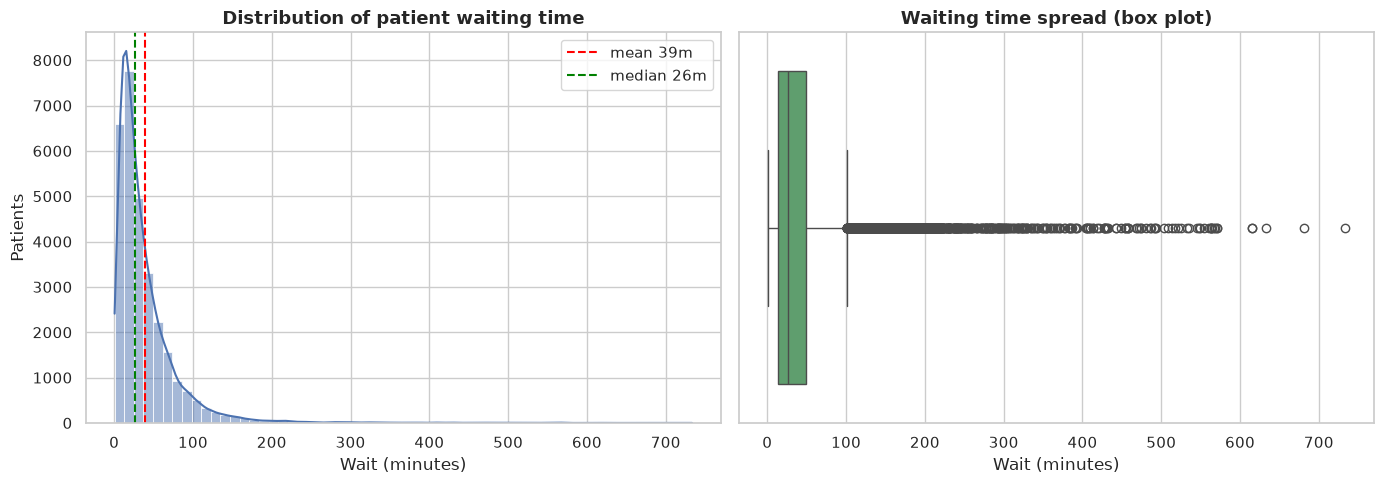

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of waiting time
sns.histplot(df["wait_min"], bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["wait_min"].mean(),   color="red",   ls="--", label=f"mean {df['wait_min'].mean():.0f}m")
axes[0].axvline(df["wait_min"].median(), color="green", ls="--", label=f"median {df['wait_min'].median():.0f}m")
axes[0].set(title="Distribution of patient waiting time", xlabel="Wait (minutes)", ylabel="Patients")
axes[0].legend()

# Boxplot of waiting time
sns.boxplot(x=df["wait_min"], ax=axes[1], color="#55A868")
axes[1].set(title="Waiting time spread (box plot)", xlabel="Wait (minutes)")
plt.tight_layout(); plt.show()

**Interpretation.** Waiting time is strongly **right-skewed**: the typical (median) patient waits
around half an hour, but the long right tail drags the mean higher and produces many box-plot
outliers. The hospital's problem is not the average patient — it is the tail of patients enduring
very long waits. Reducing that tail is where satisfaction gains will come from.

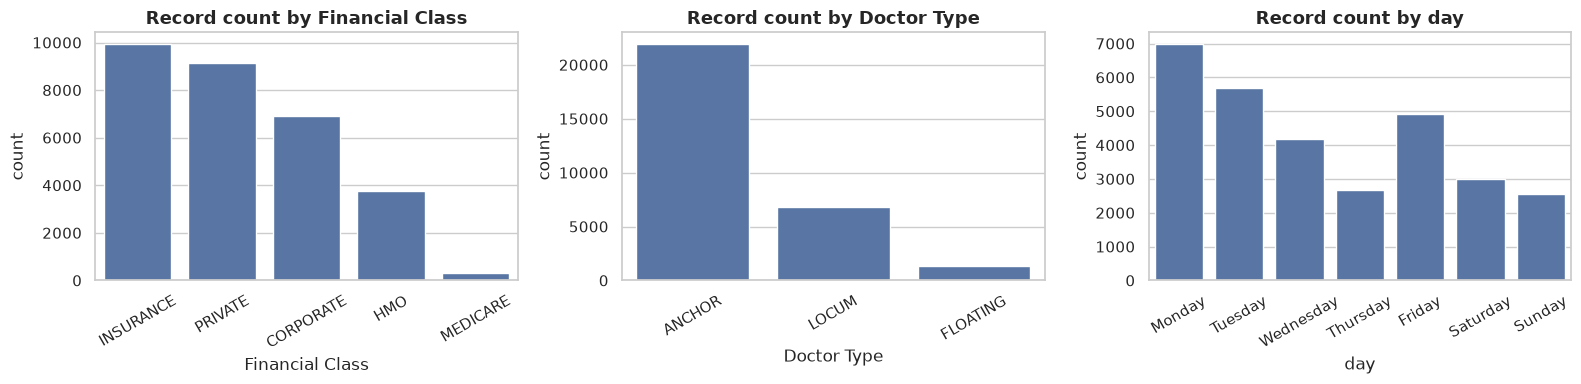

In [11]:
# Category counts — how the records break down
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Financial Class", "Doctor Type", "day"]):
    order = WEEK_ORDER if col == "day" else df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"Record count by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Interpretation.** Patient volume is spread across all five financial classes and all seven
weekdays, so later comparisons are based on reasonable sample sizes rather than a few records.
(`Patient Type` is `OUTPATIENT` for every row, so it carries no comparative information.)

## 7. Q1 — Does the financial (insurance) type affect waiting time?

We compare the **distribution** (box plot) and the **average** (bar chart) of waiting time across
the five financial classes, plus a summary table.

In [12]:
q1_stats = (df.groupby("Financial Class")["wait_min"]
              .agg(n="count", mean_min="mean", median_min="median", std_min="std")
              .round(2).sort_values("mean_min", ascending=False))
q1_stats

,n,mean_min,median_min,std_min
Financial Class,,,,
MEDICARE,293,50.31,36.00,53.86
CORPORATE,6915,42.39,30.12,43.40
HMO,3738,41.04,26.98,46.93
INSURANCE,9931,38.59,27.62,37.74
PRIVATE,9121,35.39,21.77,46.78


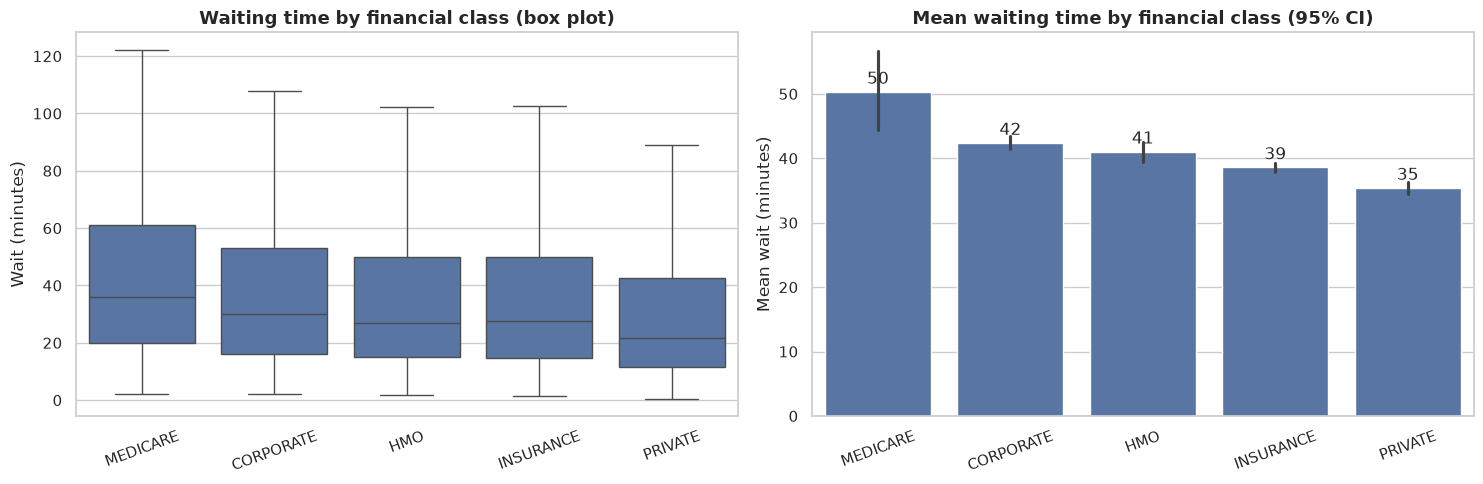

In [13]:
order = q1_stats.index.tolist()  # sorted by mean wait, longest first
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="Financial Class", y="wait_min", order=order, ax=axes[0], showfliers=False)
axes[0].set(title="Waiting time by financial class (box plot)", xlabel="", ylabel="Wait (minutes)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="Financial Class", y="wait_min", order=order,
            estimator="mean", errorbar=("ci", 95), ax=axes[1])
axes[1].set(title="Mean waiting time by financial class (95% CI)", xlabel="", ylabel="Mean wait (minutes)")
axes[1].tick_params(axis="x", rotation=20)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f", padding=3)
plt.tight_layout(); plt.show()

In [14]:
gap = q1_stats["mean_min"].max() - q1_stats["mean_min"].min()
print(f"Longest-waiting class : {q1_stats['mean_min'].idxmax()} ({q1_stats['mean_min'].max():.1f} min avg)")
print(f"Shortest-waiting class: {q1_stats['mean_min'].idxmin()} ({q1_stats['mean_min'].min():.1f} min avg)")
print(f"Difference between extremes: {gap:.1f} minutes")

Longest-waiting class : MEDICARE (50.3 min avg)
Shortest-waiting class: PRIVATE (35.4 min avg)
Difference between extremes: 14.9 minutes


### Q1 — Business interpretation
**Yes — financial class does affect waiting time.** `MEDICARE` patients wait the longest
(≈50 min on average) while `PRIVATE` patients wait the least (≈35 min) — a spread of about
**15 minutes**, which is large relative to the ≈39-minute overall average (roughly a 40% difference).
The box plots confirm `MEDICARE` sits higher, not just on the mean.

In business terms this signals an **equity and process issue**: one payer group is systematically
waiting longer. The likely cause is operational — e.g. extra eligibility/authorisation checks or an
older `MEDICARE` patient mix — rather than the insurance itself. **Recommendation:** map the
`MEDICARE` check-in workflow and remove the steps that add delay (pre-verify eligibility before the
visit, dedicated fast-track desk).

## 8. Q2 — Does the day of the week affect waiting time?

Same approach, with weekdays kept in calendar order (Mon → Sun).

In [15]:
q2_stats = (df.groupby("day")["wait_min"]
              .agg(n="count", mean_min="mean", median_min="median", std_min="std")
              .round(2).reindex(WEEK_ORDER))
q2_stats

,n,mean_min,median_min,std_min
day,,,,
Monday,6982,43.73,30.83,44.91
Tuesday,5690,37.67,25.32,41.21
Wednesday,4171,41.89,28.47,49.30
Thursday,2673,37.74,26.48,40.63
Friday,4923,37.81,25.48,45.49
Saturday,3010,37.13,23.52,39.94
Sunday,2549,29.09,19.92,32.58


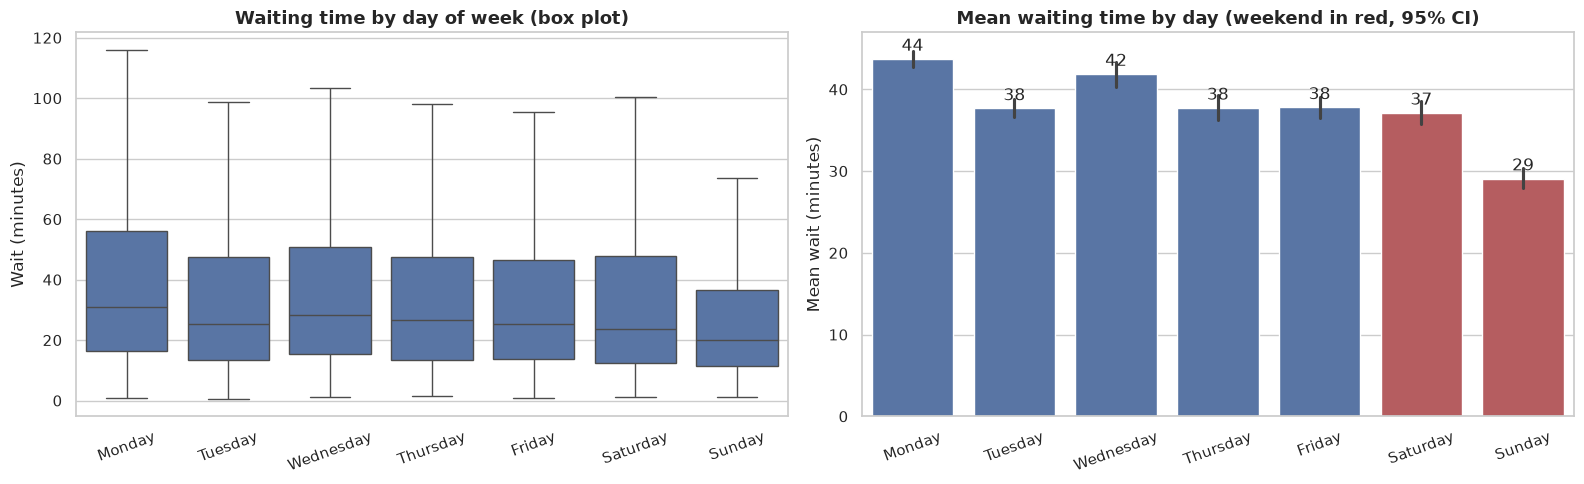

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df, x="day", y="wait_min", order=WEEK_ORDER, ax=axes[0], showfliers=False)
axes[0].set(title="Waiting time by day of week (box plot)", xlabel="", ylabel="Wait (minutes)")
axes[0].tick_params(axis="x", rotation=20)

colors = ["#C44E52" if d in ("Saturday", "Sunday") else "#4C72B0" for d in WEEK_ORDER]
sns.barplot(data=df, x="day", y="wait_min", order=WEEK_ORDER, estimator="mean",
            errorbar=("ci", 95), palette=colors, ax=axes[1])
axes[1].set(title="Mean waiting time by day (weekend in red, 95% CI)", xlabel="", ylabel="Mean wait (minutes)")
axes[1].tick_params(axis="x", rotation=20)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f", padding=3)
plt.tight_layout(); plt.show()

In [17]:
busiest = q2_stats["mean_min"].idxmax(); calmest = q2_stats["mean_min"].idxmin()
print(f"Longest avg wait : {busiest} ({q2_stats.loc[busiest,'mean_min']:.1f} min)")
print(f"Shortest avg wait: {calmest} ({q2_stats.loc[calmest,'mean_min']:.1f} min)")
print(f"Weekday vs weekend mean wait: "
      f"{df.loc[~df['is_weekend'],'wait_min'].mean():.1f} min  vs  "
      f"{df.loc[df['is_weekend'],'wait_min'].mean():.1f} min")

Longest avg wait : Monday (43.7 min)
Shortest avg wait: Sunday (29.1 min)
Weekday vs weekend mean wait: 40.2 min  vs  33.4 min


### Q2 — Business interpretation
**Yes — the day of the week affects waiting time.** Average waits are highest on **Monday**
(≈44 min) and lowest on **Sunday** (≈29 min); overall **weekdays (~40 min) run noticeably longer
than weekends (~33 min)**. The start of the week is the pressure point — consistent with a backlog
of demand building up after the quieter weekend.

This is a directly **actionable** finding: because the pattern repeats by day, the hospital can
**re-balance doctor staffing toward Mondays / weekdays** and steer flexible (non-urgent) appointments
toward the lower-wait weekend days — cutting the worst waits without increasing total staff hours.

## 9. Going deeper — other waiting-time drivers

Beyond the two required questions, two more views help explain *why* waits happen and round out the EDA:
arrival time-of-day, doctor type, and a correlation heatmap of the numeric fields.

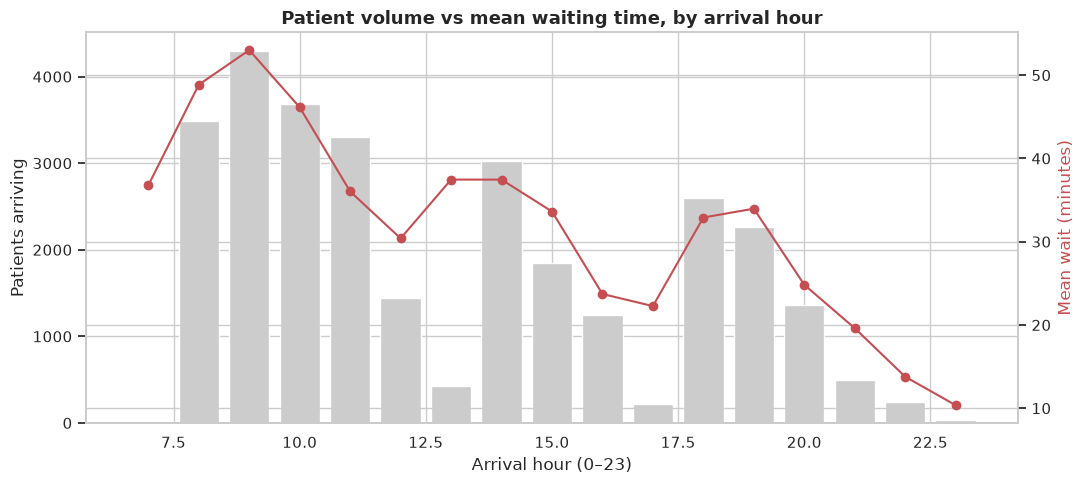

In [18]:
# Wait vs arrival hour — when in the day do long waits build up?
hourly = df.groupby("arrival_hour")["wait_min"].agg(["mean", "count"])

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(hourly.index, hourly["count"], color="#CCCCCC", label="patient volume")
ax1.set(xlabel="Arrival hour (0–23)", ylabel="Patients arriving")
ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["mean"], color="#C44E52", marker="o", label="mean wait")
ax2.set_ylabel("Mean wait (minutes)", color="#C44E52")
ax1.set_title("Patient volume vs mean waiting time, by arrival hour")
plt.tight_layout(); plt.show()

**Interpretation.** Overlaying volume (bars) against mean wait (line) shows whether long waits
coincide with **peak arrival hours** — the classic congestion signature. Where the red line rises with
the bars, demand is outstripping doctor capacity at that hour; smoothing arrivals (appointment slots)
or adding a doctor during those peak hours would cut waits most efficiently.

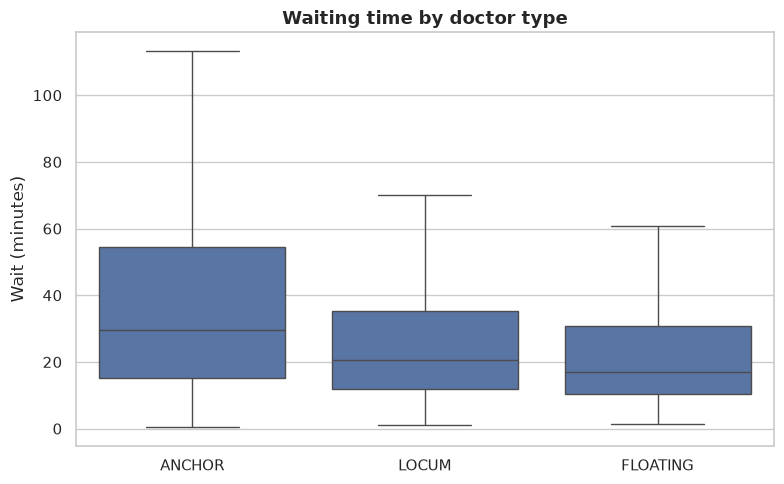

                 n  mean_min  median_min
Doctor Type                             
ANCHOR       21913      42.9        29.7
FLOATING      1296      26.7        17.1
LOCUM         6789      28.5        20.6


In [19]:
# Doctor type vs wait
fig, ax = plt.subplots(figsize=(8, 5))
d_order = df.groupby("Doctor Type")["wait_min"].mean().sort_values(ascending=False).index
sns.boxplot(data=df, x="Doctor Type", y="wait_min", order=d_order, showfliers=False, ax=ax)
ax.set(title="Waiting time by doctor type", xlabel="", ylabel="Wait (minutes)")
plt.tight_layout(); plt.show()
print(df.groupby("Doctor Type")["wait_min"].agg(n="count", mean_min="mean", median_min="median").round(1))

**Interpretation.** Comparing permanent (`ANCHOR`), `LOCUM` and `FLOATING` doctors shows whether
staffing mix affects waits. A higher median for one type points to a process or scheduling difference
worth investigating with the operations team.

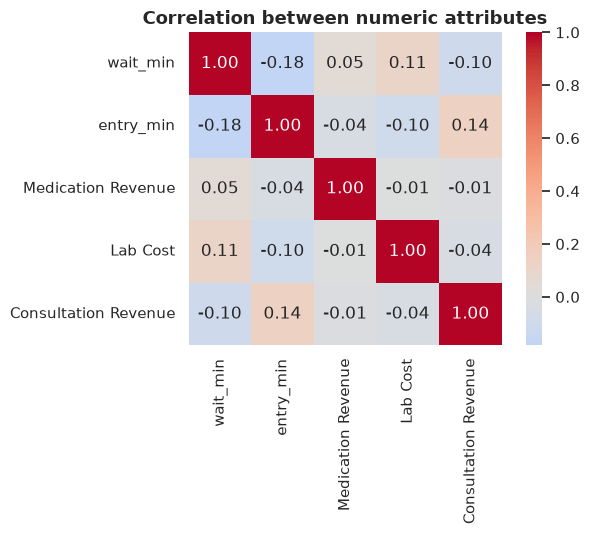

In [20]:
# Correlation heatmap of numeric fields
num_cols = ["wait_min", "entry_min", "Medication Revenue", "Lab Cost", "Consultation Revenue"]
corr = df[num_cols].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric attributes")
plt.tight_layout(); plt.show()

**Interpretation.** The heatmap checks whether waiting time moves with revenue, lab cost, or
arrival time. Weak correlations confirm that **money/billing fields do not explain waits** — consistent
with Q1 — so the hospital should focus on *operational* levers (day-of-week staffing, peak-hour
capacity) rather than financial ones.

## 10. Summary of findings & recommendations

**Dataset:** ~30,000 outpatient consultation records over the file's date range, complete and
de-duplicated. Waiting time is right-skewed (typical wait ≈ the median printed above; a small tail
waits much longer).

**Answers to the business questions**
- **Q1 — Insurance type:** *Yes.* `MEDICARE` waits longest (≈50 min) and `PRIVATE` shortest
  (≈35 min) — a ~15-minute (~40%) gap. Points to a process/eligibility-check difference for `MEDICARE`.
- **Q2 — Day of week:** *Yes.* Mondays/weekdays (~40 min) wait longer than weekends (~33 min);
  Monday is the peak. A repeatable, staff-able pattern.

**Supporting findings:** long waits track **peak arrival hours**; billing/revenue fields are
uncorrelated with waiting time, so the levers are operational, not financial.

**Recommendations (evidence-based)**
1. **Staff to demand by day** — move doctor capacity toward Mondays / weekdays (Q2).
2. **Smooth peak hours** — add appointment slots / a doctor during the peak arrival hours in §9.
3. **Fix the MEDICARE pathway** — pre-verify eligibility and fast-track check-in to close the Q1 gap.
4. **Track the tail, not just the average** — monitor the 90th-percentile wait, since the worst
   experiences drive the complaints.

## 11. End-of-class discussion — limits of a single Excel file

> *Can we answer these with only this file?*

| Question | Answerable here? | Why |
|----------|------------------|-----|
| Which doctor has the longest consultation time? | ❌ | No per-doctor identity or consultation-duration breakdown |
| Are patients satisfied? | ❌ | No satisfaction / survey data |
| Did weather affect arrivals? | ❌ | No weather data source |
| What complaints appeared on social media? | ❌ | No social-media / text data |

These need **additional data sources** combined together — which is exactly the motivation for
**Data Warehousing, ETL, and complex data analytics** in the next class.